# Credit Card Fraud Detection — Data Preprocessing

This notebook prepares `creditcard.csv` for model training.

**Target column:** `Class`  
**Scaling:** Only `Time` and `Amount` are scaled because `V1`–`V28` are already PCA-transformed.  
**Data leakage prevention:** The scaler is fitted on the training data only.

Keep this notebook in the same project folder as `creditcard.csv`.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20

## 2. Load the dataset

In [2]:
# The CSV file should be in the same folder as this notebook.
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Explore the dataset

In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 4. Check missing values

In [4]:
missing_values = df.isnull().sum()

print("Missing values by column:")
display(missing_values[missing_values > 0])

print("Total missing values:", int(missing_values.sum()))

Missing values by column:


Series([], dtype: int64)

Total missing values: 0


## 5. Remove duplicate records

Duplicate rows are removed before splitting the data. The original dataset is not modified.

In [5]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Duplicate rows found: 1081
Shape after removing duplicates: (283726, 31)


## 6. Handle missing values (if any)

For this dataset, missing values are not normally expected. If any are present, this cell fills numeric feature columns with their median. The target column must not contain missing labels.

In [6]:
if "Class" not in df.columns:
    raise ValueError("Target column 'Class' was not found in the dataset.")

if df["Class"].isna().any():
    raise ValueError("The target column 'Class' contains missing values. Please inspect these rows.")

feature_columns = df.drop(columns=["Class"]).select_dtypes(include=np.number).columns
df[feature_columns] = df[feature_columns].fillna(df[feature_columns].median())

print("Missing values remaining:", int(df.isnull().sum().sum()))

Missing values remaining: 0


## 7. Separate features and target

In [7]:
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts().sort_index())

Features shape: (283726, 30)
Target shape: (283726,)

Target classes:
Class
0    283253
1       473
Name: count, dtype: int64


## 8. Check class imbalance

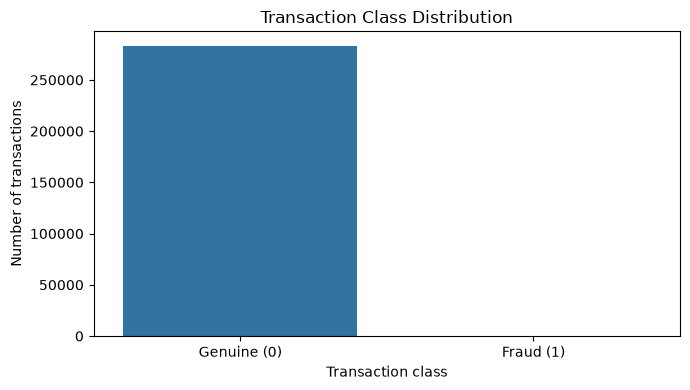

Class percentages:


Class
0    99.83329
1     0.16671
Name: Percentage, dtype: float64

In [8]:
class_counts = y.value_counts().sort_index()
class_names = ["Genuine (0)", "Fraud (1)"]

plt.figure(figsize=(7, 4))
sns.barplot(x=class_names, y=[class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Transaction Class Distribution")
plt.xlabel("Transaction class")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

print("Class percentages:")
display((y.value_counts(normalize=True).sort_index() * 100).rename("Percentage"))

## 9. Split into training and testing sets

Stratification preserves the genuine/fraud class proportions in both sets. No resampling is performed here; imbalance can be handled during model training.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (226980, 30)
Testing features: (56746, 30)

Training target distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing target distribution:
Class
0    56651
1       95
Name: count, dtype: int64


## 10. Scale `Time` and `Amount`

`V1`–`V28` are PCA-transformed features, so this notebook leaves them unchanged. The scaler is fitted only on `X_train`, then applied to both sets.

In [10]:
columns_to_scale = ["Time", "Amount"]

missing_scale_columns = [col for col in columns_to_scale if col not in X_train.columns]
if missing_scale_columns:
    raise ValueError(f"Expected columns not found: {missing_scale_columns}")

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test.loc[:, columns_to_scale] = scaler.transform(X_test[columns_to_scale])

print("Scaling completed.")
display(X_train[columns_to_scale].describe())

Scaling completed.


,Time,Amount
count,2.269800e+05,2.269800e+05
mean,-1.522636e-16,7.487965e-17
std,1.000002e+00,1.000002e+00
min,-1.998400e+00,-3.596386e-01
25%,-8.561822e-01,-3.364866e-01
50%,-2.123526e-01,-2.697972e-01
75%,9.363191e-01,-4.287453e-02
max,1.640237e+00,7.962087e+01


## 11. Final preprocessing summary

In [11]:
print("DATA PREPROCESSING COMPLETED")
print("-" * 40)
print(f"Rows after cleaning: {len(df):,}")
print(f"Number of features: {X_train.shape[1]}")
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")
print(f"Training fraud cases: {(y_train == 1).sum():,}")
print(f"Testing fraud cases: {(y_test == 1).sum():,}")

print("\nVariables ready for the next notebook:")
print("X_train, X_test, y_train, y_test")
print("\nNote: These variables are available in this notebook's kernel.")
print("A separate notebook has its own kernel; use a shared .py module or CSV files to pass data between notebooks.")

DATA PREPROCESSING COMPLETED
----------------------------------------
Rows after cleaning: 283,726
Number of features: 30
Training samples: 226,980
Testing samples: 56,746
Training fraud cases: 378
Testing fraud cases: 95

Variables ready for the next notebook:
X_train, X_test, y_train, y_test

Note: These variables are available in this notebook's kernel.
A separate notebook has its own kernel; use a shared .py module or CSV files to pass data between notebooks.


## Output variables for model training

After running all cells, the following variables are ready to use in this notebook:

- `X_train`: scaled training features
- `X_test`: scaled testing features
- `y_train`: training labels
- `y_test`: testing labels
- `scaler`: fitted `StandardScaler`

**Important:** Run the cells from top to bottom. This notebook does not create a `.pkl` file.